# 12 — NN stacked on the LDA

An MLP (one hidden layer of 64) on `[LDA log-posteriors, features]`: it sits on top of the LDA and
corrects it (`src/nn.py`, `LDAStack`). The training posteriors are out-of-fold (5 contiguous blocks per class), otherwise
the MLP learns to trust the LDA more than it deserves on new data.

Calibration (`loso`): fine-tunes the MLP's output layer and leaves the LDA as it is. Adapting the LDA instead
(`LDA.adapt`) sharpens its posteriors beyond what the MLP saw in training and the fixed MLP misreads them: balanced
accuracy fell to ~0.17 (chance 0.08).

Same protocol as `10`: DB5 exercise 1, train on repetitions 1–4, test on 5–6, every regime. Writes `runs/notebooks/lda_stack.json` for `15`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src import report

if Path.cwd().name == "notebooks":
    os.chdir("..")

In [2]:
FEATURES = {}
DECODER = {"decoder": {"name": "lda_stack", "params": {}}}
cfg, *data = report.features(FEATURES)
X, y, columns, info = data
print(f"{len(y)} windows x {X.shape[1]} features")

140145 windows x 48 features


## Every regime

In [3]:
summary = report.run_regimes({**FEATURES, **DECODER}, data)
latency = report.latency_us({**FEATURES, **DECODER}, data)
report.save(DECODER["decoder"]["name"], summary, latency)
print(f"decoder latency: {latency:.0f} µs per window")

per_user balanced 0.709 | macro-F1 0.667 | 21 s


pooled   balanced 0.548 | macro-F1 0.513 | 10 s


loso     balanced 0.366 | macro-F1 0.348 | 153 s


decoder latency: 19 µs per window


Against the LDA baseline (from `10`):

In [4]:
summaries = report.load_all()
names = [n for n in ("lda", DECODER["decoder"]["name"]) if n in summaries]
report.table({n: summaries[n] for n in names}).round(3)

accuracy  balanced_accuracy  macro_f1  \
decoder   regime                                            
lda       per_user     0.810              0.643     0.653   
          pooled       0.730              0.461     0.467   
          loso         0.701              0.389     0.393   
lda_stack per_user     0.797              0.709     0.667   
          pooled       0.730              0.548     0.513   
          loso         0.658              0.366     0.348   

                    worst_user_balanced  switches_per_s  latency_us  \
decoder   regime                                                      
lda       per_user                0.566           2.468       7.375   
          pooled                  0.291           3.519       7.375   
          loso                    0.234           3.690       7.375   
lda_stack per_user                0.585           2.756      18.792   
          pooled                  0.435           4.378      18.792   
          loso                    0.228           4.738      18.792   

                    evaluation_s  
decoder   regime                  
lda       per_user         0.940  
          pooled           0.156  
          loso             1.876  
lda_stack per_user        21.196  
          pooled           9.827  
          loso           153.259

## Calibration effort

Dashed: a new decoder per subject from *n* seconds per class. Solid: the decoder of the other nine subjects, adapted with them.

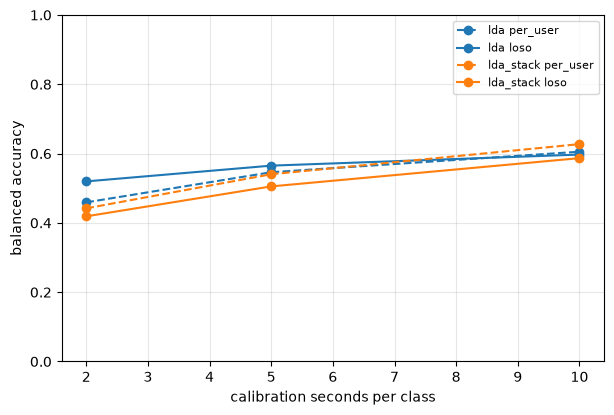

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
report.plot_calibration(ax, {n: summaries[n] for n in names})

## Confusions (per_user)

per_user    0.860
pooled      0.859
loso        0.860
Name: rest recall, dtype: float64

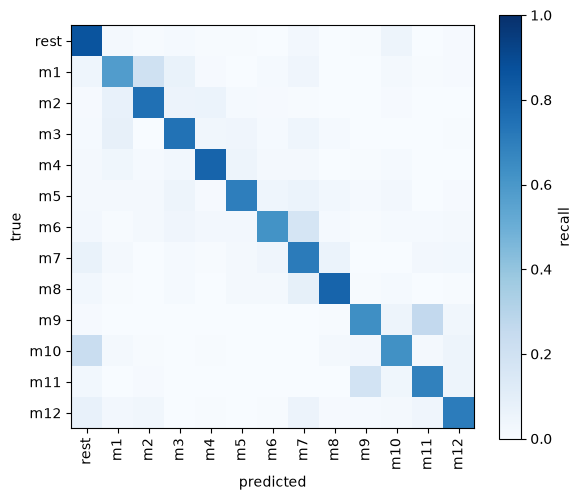

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = report.plot_confusion(ax, summary["per_user"]["y_true"], summary["per_user"]["y_pred"], info["label_names"])
fig.colorbar(im, label="recall")
pd.Series({regime: s["recall"]["rest"] for regime, s in summary.items()}, name="rest recall").round(3)